# Banana Ripeness Model — Final Test Evaluation

This version is designed to work with your **current TensorFlow/Keras environment**.

It includes a compatibility fix for older Teachable Machine `.h5` models that may raise:

```text
Unrecognized keyword arguments passed to DepthwiseConv2D: {'groups': 1}
```

The notebook evaluates the untouched test set and produces:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Classification report
- Per-image prediction CSV


## Expected folder structure

```text
machine_learning/
└── ripeness_classification/
    ├── models/
    │   ├── keras_model.h5
    │   └── labels.txt
    ├── data/
    │   └── test/
    │       ├── Overripe/
    │       ├── Ripe/
    │       └── Unripe/
    ├── evaluation/
    └── notebooks/
        └── 03_ripeness_model_evaluation_current_env.ipynb
```

Keep the test images untouched. Do not upload them into Teachable Machine training.


In [27]:
# Install only the general evaluation libraries if they are missing.
# DO NOT downgrade TensorFlow/Keras in this notebook.

# %pip install pillow pandas scikit-learn matplotlib
%pip install tf-keras==2.20.1


Note: you may need to restart the kernel to use updated packages.


In [28]:
from pathlib import Path
import sys
import re

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)

try:
    import keras
    print("Keras:", keras.__version__)
except Exception:
    pass


Python: 3.12.7
TensorFlow: 2.20.0
Keras: 3.12.0


## 1. Locate project folders

In [29]:
cwd = Path.cwd().resolve()

if cwd.name == "notebooks":
    ROOT = cwd.parent
elif (cwd / "machine_learning" / "ripeness_classification").exists():
    ROOT = cwd / "machine_learning" / "ripeness_classification"
elif (cwd / "ripeness_classification").exists():
    ROOT = cwd / "ripeness_classification"
else:
    # If your notebook is stored somewhere else, edit ROOT manually.
    ROOT = cwd.parent

MODEL_DIR = ROOT / "models"
TEST_DIR = ROOT / "data" / "test"
OUTPUT_DIR = ROOT / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT      :", ROOT)
print("MODEL_DIR :", MODEL_DIR)
print("TEST_DIR  :", TEST_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)


ROOT      : C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification
MODEL_DIR : C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\models
TEST_DIR  : C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\data\test
OUTPUT_DIR: C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\evaluation


## 2. Find model and labels

In [30]:
h5_files = sorted(MODEL_DIR.glob("*.h5"))

if not h5_files:
    raise FileNotFoundError(
        f"No .h5 model found in {MODEL_DIR}. "
        "Copy your Teachable Machine .h5 file into this folder."
    )

MODEL_PATH = h5_files[0]
LABELS_PATH = MODEL_DIR / "labels.txt"

if not LABELS_PATH.exists():
    raise FileNotFoundError(
        f"labels.txt not found in {MODEL_DIR}."
    )

print("Model :", MODEL_PATH.name)
print("Labels:", LABELS_PATH.name)


Model : keras_model.h5
Labels: labels.txt


## 3. Load labels and model

This cell contains the compatibility fix for older Teachable Machine H5 models.


In [31]:
import tf_keras


def load_labels(path):
    labels = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            parts = line.split(" ", 1)

            if len(parts) == 2 and parts[0].isdigit():
                labels.append(parts[1].strip())
            else:
                labels.append(line)

    return labels


class_names = load_labels(LABELS_PATH)

print("Model classes:", class_names)


# Compatibility fix for Teachable Machine's old H5 model
class CompatibleDepthwiseConv2D(
    tf_keras.layers.DepthwiseConv2D
):

    def __init__(self, *args, groups=None, **kwargs):
        super().__init__(*args, **kwargs)


model = tf_keras.models.load_model(
    MODEL_PATH,
    compile=False,
    custom_objects={
        "DepthwiseConv2D": CompatibleDepthwiseConv2D
    }
)

print("Model loaded successfully.")


Model classes: ['Overripe', 'Ripe', 'Unripe']


Model loaded successfully.


## 4. Read test images

The folder name is used as the true label.

Example:

```text
data/test/Ripe/banana_001.jpg
```

means the true class is `Ripe`.


In [32]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_items = []

if not TEST_DIR.exists():
    raise FileNotFoundError(f"Test folder not found: {TEST_DIR}")

for class_dir in sorted(TEST_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    true_label = class_dir.name

    for image_path in sorted(class_dir.rglob("*")):
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            test_items.append((image_path, true_label))

if not test_items:
    raise ValueError(
        f"No test images found inside {TEST_DIR}. "
        "Put your untouched test images into class folders first."
    )

print("Total test images:", len(test_items))

counts = pd.Series(
    [label for _, label in test_items]
).value_counts()

display(counts.rename("Number of test images").to_frame())


Total test images: 60


,Number of test images
Overripe,20
Ripe,20
Unripe,20


## 5. Teachable Machine image preprocessing

The exported image model normally expects:

- `224 × 224`
- RGB
- center crop / fit
- normalization to `[-1, 1]`


In [33]:
def preprocess_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")

        image = ImageOps.fit(
            image,
            (224, 224),
            method=Image.Resampling.LANCZOS
        )

        image_array = np.asarray(image).astype(np.float32)

    image_array = (image_array / 127.5) - 1.0

    return np.expand_dims(image_array, axis=0)


## 6. Predict all test images

In [34]:
results = []

for i, (image_path, true_label) in enumerate(test_items, start=1):
    data = preprocess_image(image_path)

    scores = model.predict(
        data,
        verbose=0
    )[0]

    pred_index = int(np.argmax(scores))
    pred_label = class_names[pred_index]
    confidence = float(scores[pred_index])

    row = {
        "filename": image_path.name,
        "true_label": true_label,
        "predicted_label": pred_label,
        "confidence": confidence,
        "correct": true_label == pred_label,
    }

    for class_index, class_name in enumerate(class_names):
        if class_index < len(scores):
            row[f"prob_{class_name}"] = float(scores[class_index])

    results.append(row)

    if i % 20 == 0 or i == len(test_items):
        print(f"Processed {i}/{len(test_items)}")

results_df = pd.DataFrame(results)

display(results_df.head(10))


Processed 20/60
Processed 40/60
Processed 60/60


,filename,true_label,predicted_label,confidence,correct,prob_Overripe,prob_Ripe,prob_Unripe
0,musa-acuminata-mold-e1b0bd7a-1d0a-11ec-a43f-d8...,Overripe,Overripe,0.999827,True,0.999827,1.726282e-04,3.852805e-08
1,musa-acuminata-mold-e1b7e3ee-1d0a-11ec-99f8-d8...,Overripe,Overripe,0.999952,True,0.999952,4.770591e-05,5.923505e-07
2,musa-acuminata-mold-e1c630e6-1d0a-11ec-8b9a-d8...,Overripe,Overripe,0.999981,True,0.999981,1.872778e-05,2.383884e-07
3,musa-acuminata-mold-e1c630e6-1d0a-11ec-8b9a-d8...,Overripe,Overripe,0.999983,True,0.999983,1.666055e-05,1.033286e-07
4,musa-acuminata-mold-e1d47dce-1d0a-11ec-a1ed-d8...,Overripe,Overripe,0.999998,True,0.999998,1.463208e-06,7.109457e-07
5,musa-acuminata-mold-e2a3dc4f-1d0a-11ec-aa8b-d8...,Overripe,Overripe,1.000000,True,1.000000,3.054452e-07,1.837030e-08
6,musa-acuminata-mold-e2afc439-1d0a-11ec-b7ea-d8...,Overripe,Overripe,1.000000,True,1.000000,3.443070e-07,6.717031e-10
7,musa-acuminata-mold-e2edbc4f-1d0a-11ec-928c-d8...,Overripe,Overripe,0.999979,True,0.999979,2.035674e-05,1.022452e-06
8,musa-acuminata-mold-e2f9a701-1d0a-11ec-9de6-d8...,Overripe,Overripe,0.999999,True,0.999999,5.631646e-07,3.736341e-08
9,musa-acuminata-mold-e3bf7a45-1d0a-11ec-bc01-d8...,Overripe,Overripe,0.999745,True,0.999745,3.610966e-06,2.512407e-04


## 7. Final test metrics

In [35]:
y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]

evaluation_labels = list(class_names)

for label in sorted(set(y_true)):
    if label not in evaluation_labels:
        evaluation_labels.append(label)

accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=evaluation_labels,
    average="macro",
    zero_division=0,
)

precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=evaluation_labels,
    average="weighted",
    zero_division=0,
)

summary_df = pd.DataFrame([{
    "test_images": len(results_df),
    "accuracy": accuracy,
    "precision_macro": precision_macro,
    "recall_macro": recall_macro,
    "f1_macro": f1_macro,
    "precision_weighted": precision_weighted,
    "recall_weighted": recall_weighted,
    "f1_weighted": f1_weighted,
}])

display(summary_df.style.format({
    "accuracy": "{:.4f}",
    "precision_macro": "{:.4f}",
    "recall_macro": "{:.4f}",
    "f1_macro": "{:.4f}",
    "precision_weighted": "{:.4f}",
    "recall_weighted": "{:.4f}",
    "f1_weighted": "{:.4f}",
}))


,test_images,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,60,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 8. Classification report

In [36]:
report_dict = classification_report(
    y_true,
    y_pred,
    labels=evaluation_labels,
    target_names=evaluation_labels,
    zero_division=0,
    output_dict=True,
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df)


,precision,recall,f1-score,support
Overripe,1.0,1.0,1.0,20.0
Ripe,1.0,1.0,1.0,20.0
Unripe,1.0,1.0,1.0,20.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,60.0
weighted avg,1.0,1.0,1.0,60.0


## 9. Confusion matrix

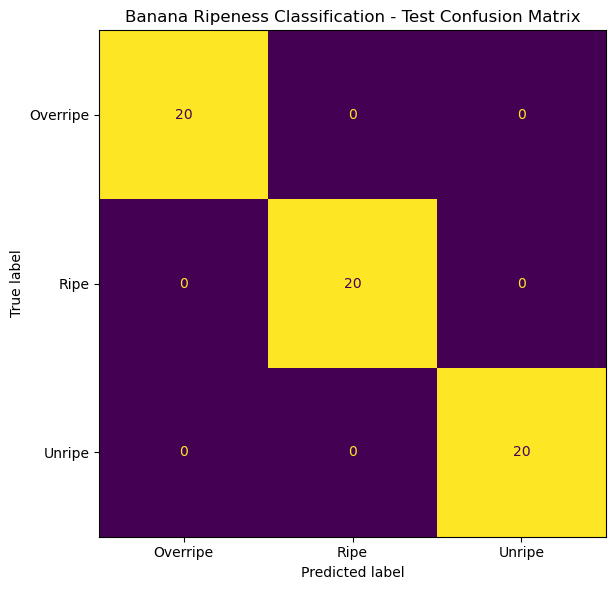

In [37]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=evaluation_labels,
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=evaluation_labels,
)

disp.plot(
    ax=ax,
    cmap=None,
    colorbar=False,
    values_format="d"
)

ax.set_title("Banana Ripeness Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 10. Incorrect predictions

In [38]:
wrong_df = results_df[
    results_df["correct"] == False
].copy()

wrong_df = wrong_df.sort_values(
    "confidence",
    ascending=False
)

print(
    f"Incorrect predictions: {len(wrong_df)} "
    f"out of {len(results_df)}"
)

display(wrong_df)


Incorrect predictions: 0 out of 60


,filename,true_label,predicted_label,confidence,correct,prob_Overripe,prob_Ripe,prob_Unripe


## 11. Save evaluation results

In [39]:
results_path = OUTPUT_DIR / "ripeness_test_predictions.csv"
summary_path = OUTPUT_DIR / "ripeness_test_summary.csv"
report_path = OUTPUT_DIR / "ripeness_classification_report.csv"
cm_path = OUTPUT_DIR / "ripeness_confusion_matrix.png"

results_df.to_csv(results_path, index=False)
summary_df.to_csv(summary_path, index=False)
report_df.to_csv(report_path)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=evaluation_labels,
)

disp.plot(
    ax=ax,
    cmap=None,
    colorbar=False,
    values_format="d"
)

ax.set_title("Banana Ripeness Classification - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.close()

print("Saved:")
print("-", results_path)
print("-", summary_path)
print("-", report_path)
print("-", cm_path)


Saved:
- C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\evaluation\ripeness_test_predictions.csv
- C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\evaluation\ripeness_test_summary.csv
- C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\evaluation\ripeness_classification_report.csv
- C:\Users\enton\Project\python\banana_quality_ripeness_assessment_system\machine_learning\ripeness_classification\evaluation\ripeness_confusion_matrix.png


## Report interpretation

- **Accuracy**: percentage of all test images classified correctly.
- **Precision**: when the model predicts a class, how often it is correct.
- **Recall**: how many actual images of a class are correctly detected.
- **F1-score**: balance between precision and recall.
- **Confusion matrix**: shows which ripeness classes are confused with each other.

Use these untouched test-set results as your final model evaluation.
